In [16]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print('TensorFlow version: ',tf.__version__)
print('Numpy version: ',np.__version__)

TensorFlow version:  2.21.0
Numpy version:  2.1.3


In [10]:
fashion_mnist = keras.datasets.fashion_mnist
(X_train, y_train),(X_test, y_test) = fashion_mnist.load_data()

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [11]:
class_names = [ "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"]
for i, name in enumerate(class_names):
  print(i," : ",name)



0  :  T-shirt/top
1  :  Trouser
2  :  Pullover
3  :  Dress
4  :  Coat
5  :  Sandal
6  :  Shirt
7  :  Sneaker
8  :  Bag
9  :  Ankle boot


In [12]:
print("Training images:", X_train.shape)
print("Training labels:", y_train.shape)
print("Testing images:", X_test.shape)
print("Testing labels:", y_test.shape)

Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)


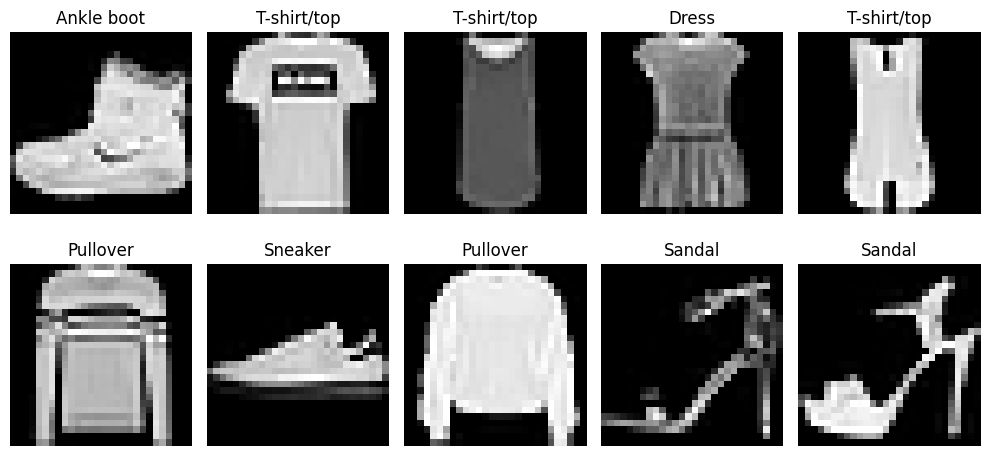

In [13]:
plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i], cmap="gray")
    plt.title(class_names[y_train[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [14]:
#Preprocessing
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

# CNN expects image height, width, and channel dimensions
X_train = X_train[..., np.newaxis]
X_test = X_test[..., np.newaxis]

print("Processed training shape:", X_train.shape)

Processed training shape: (60000, 28, 28, 1)


In [17]:
#CNN MODEL
model = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121,930 (476.29 KB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)

In [18]:
#Training
history = model.fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.1
)

Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 45s 52ms/step - accuracy: 0.8097 - loss: 0.5185 - val_accuracy: 0.8540 - val_loss: 0.3958
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 41s 49ms/step - accuracy: 0.8756 - loss: 0.3434 - val_accuracy: 0.8835 - val_loss: 0.3129
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 41s 49ms/step - accuracy: 0.8905 - loss: 0.3002 - val_accuracy: 0.8857 - val_loss: 0.3055
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 41s 49ms/step - accuracy: 0.9024 - loss: 0.2679 - val_accuracy: 0.8975 - val_loss: 0.2800
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 43s 50ms/step - accuracy: 0.9111 - loss: 0.2450 - val_accuracy: 0.9037 - val_loss: 0.2609


In [19]:
#Evaluate Performance
test_loss, test_accuracy = model.evaluate(X_test, y_test)

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.2%}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9005 - loss: 0.2818
Test loss: 0.2818
Test accuracy: 90.05%


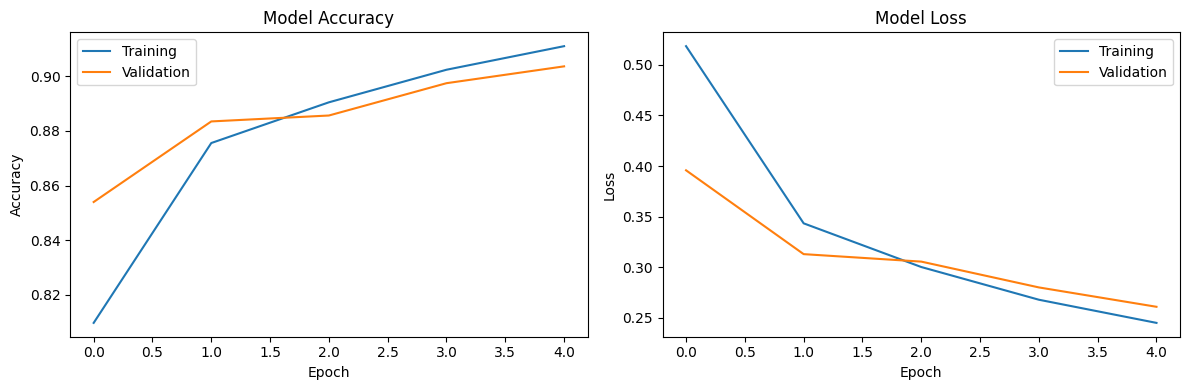

In [20]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

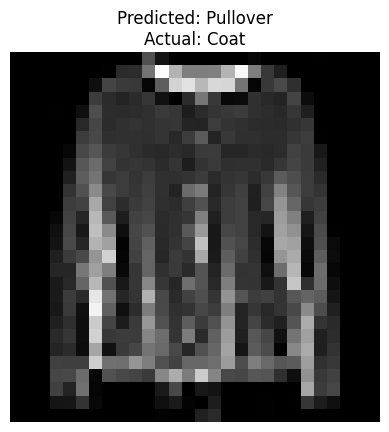

Prediction probabilities:
T-shirt/top: 0.16%
Trouser: 0.01%
Pullover: 61.46%
Dress: 0.01%
Coat: 22.02%
Sandal: 0.00%
Shirt: 16.34%
Sneaker: 0.00%
Bag: 0.00%
Ankle boot: 0.00%


In [21]:
#Prediction
index = 25

image = X_test[index]
prediction = model.predict(image[np.newaxis, ...], verbose=0)

predicted_class = np.argmax(prediction[0])
actual_class = y_test[index]

plt.imshow(image.squeeze(), cmap="gray")
plt.title(
    f"Predicted: {class_names[predicted_class]}\n"
    f"Actual: {class_names[actual_class]}"
)
plt.axis("off")
plt.show()

print("Prediction probabilities:")
for name, probability in zip(class_names, prediction[0]):
    print(f"{name}: {probability:.2%}")

In [22]:
#Check for overfit/underfit
print("Final training accuracy:",
      f"{history.history['accuracy'][-1]:.2%}")

print("Final validation accuracy:",
      f"{history.history['val_accuracy'][-1]:.2%}")

print("Test accuracy:",
      f"{test_accuracy:.2%}")

Final training accuracy: 91.11%
Final validation accuracy: 90.37%
Test accuracy: 90.05%


In [23]:
from sklearn.metrics import classification_report

predictions = model.predict(X_test, verbose=0)
predicted_labels = np.argmax(predictions, axis=1)

print(classification_report(
    y_test,
    predicted_labels,
    target_names=class_names,
    digits=3
))

              precision    recall  f1-score   support

 T-shirt/top      0.831     0.878     0.854      1000
     Trouser      0.988     0.982     0.985      1000
    Pullover      0.797     0.902     0.846      1000
       Dress      0.907     0.906     0.906      1000
        Coat      0.849     0.824     0.836      1000
      Sandal      0.987     0.971     0.979      1000
       Shirt      0.772     0.635     0.697      1000
     Sneaker      0.935     0.978     0.956      1000
         Bag      0.962     0.979     0.970      1000
  Ankle boot      0.973     0.950     0.962      1000

    accuracy                          0.900     10000
   macro avg      0.900     0.900     0.899     10000
weighted avg      0.900     0.900     0.899     10000



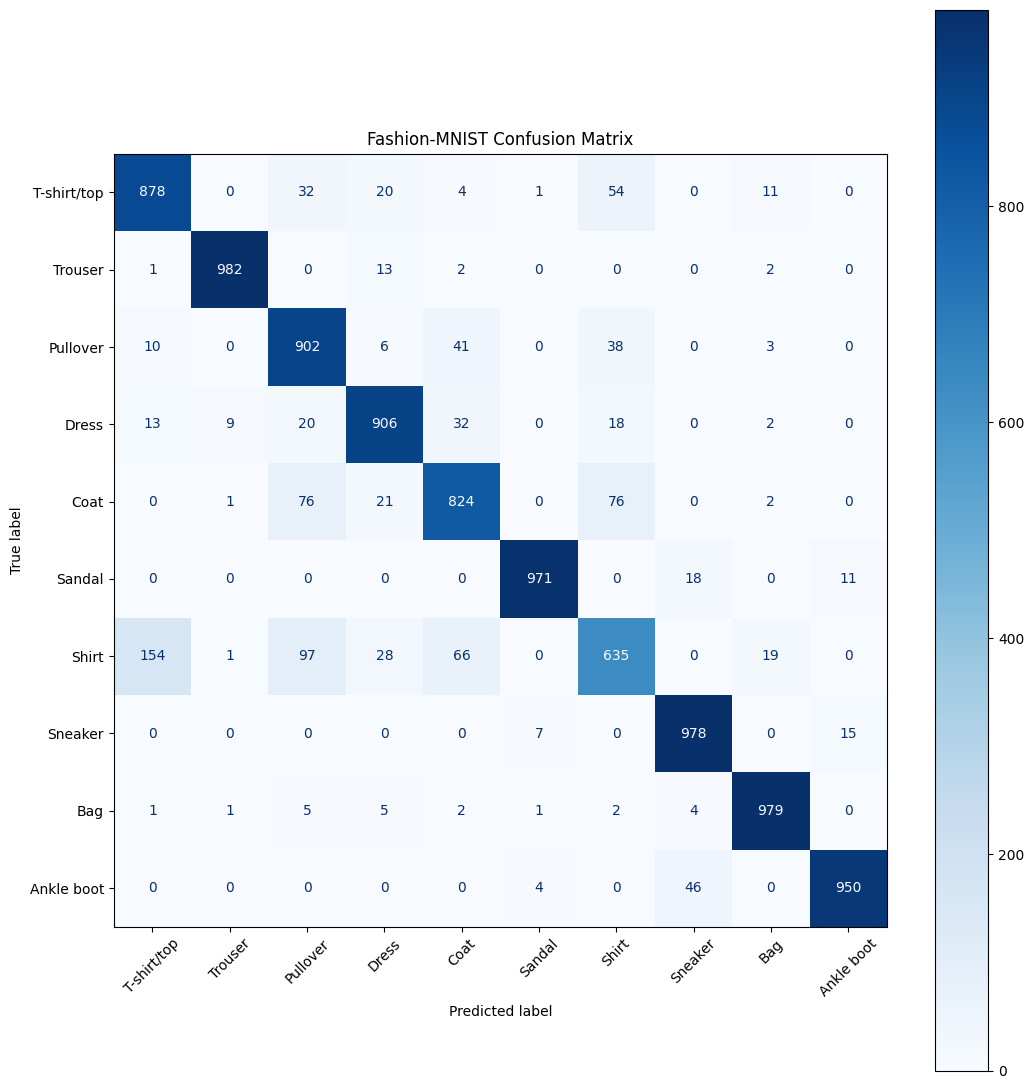

In [24]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, predicted_labels)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(11, 11))
disp.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45,
    values_format="d"
)
plt.title("Fashion-MNIST Confusion Matrix")
plt.tight_layout()
plt.show()

In [25]:
#There is a confusion among t-shirts, pullover or coat. Here is a controlled experiment hope to see model predicting right.
#Revised model
model_v2 = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),

    layers.Conv2D(32, (3, 3), padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(10, activation="softmax")
])

model_v2.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model_v2.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 32)     │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 421,930 (1.61 MB)

 Trainable params: 421,738 (1.61 MB)

 Non-trainable params: 192 (768.00 B)

In [26]:
#Training the revised model
history_v2 = model_v2.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.1,
    callbacks=[
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=2,
            restore_best_weights=True
        )
    ]
)

Epoch 1/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 103s 118ms/step - accuracy: 0.8222 - loss: 0.5001 - val_accuracy: 0.8713 - val_loss: 0.3429
Epoch 2/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 131s 105ms/step - accuracy: 0.8770 - loss: 0.3424 - val_accuracy: 0.8913 - val_loss: 0.2933
Epoch 3/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 87s 103ms/step - accuracy: 0.8930 - loss: 0.2933 - val_accuracy: 0.8992 - val_loss: 0.2724
Epoch 4/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 139s 100ms/step - accuracy: 0.9011 - loss: 0.2701 - val_accuracy: 0.9052 - val_loss: 0.2612
Epoch 5/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 142s 100ms/step - accuracy: 0.9094 - loss: 0.2472 - val_accuracy: 0.9112 - val_loss: 0.2432
Epoch 6/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 87s 102ms/step - accuracy: 0.9165 - loss: 0.2259 - val_accuracy: 0.9073 - val_loss: 0.2446
Epoch 7/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 86s 102ms/step - accuracy: 0.9236 - loss: 0.2106 - val_accuracy: 0.9160 - val_loss: 0.2282
Epoch 8/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 140s 100ms/step - accuracy: 0.9279 - lo

In [27]:
test_loss_v2, test_accuracy_v2 = model_v2.evaluate(
    X_test, y_test, verbose=0
)

print(f"Original test accuracy: {test_accuracy:.2%}")
print(f"Revised test accuracy:  {test_accuracy_v2:.2%}")

Original test accuracy: 90.05%
Revised test accuracy:  92.00%


In [28]:
from sklearn.metrics import classification_report

predictions_v2 = model_v2.predict(X_test, verbose=0)
labels_v2 = np.argmax(predictions_v2, axis=1)

print(classification_report(
    y_test,
    labels_v2,
    target_names=class_names,
    digits=3
))

              precision    recall  f1-score   support

 T-shirt/top      0.844     0.899     0.871      1000
     Trouser      0.988     0.990     0.989      1000
    Pullover      0.823     0.910     0.864      1000
       Dress      0.929     0.923     0.926      1000
        Coat      0.878     0.889     0.883      1000
      Sandal      0.983     0.986     0.985      1000
       Shirt      0.840     0.686     0.755      1000
     Sneaker      0.961     0.967     0.964      1000
         Bag      0.985     0.985     0.985      1000
  Ankle boot      0.971     0.965     0.968      1000

    accuracy                          0.920     10000
   macro avg      0.920     0.920     0.919     10000
weighted avg      0.920     0.920     0.919     10000



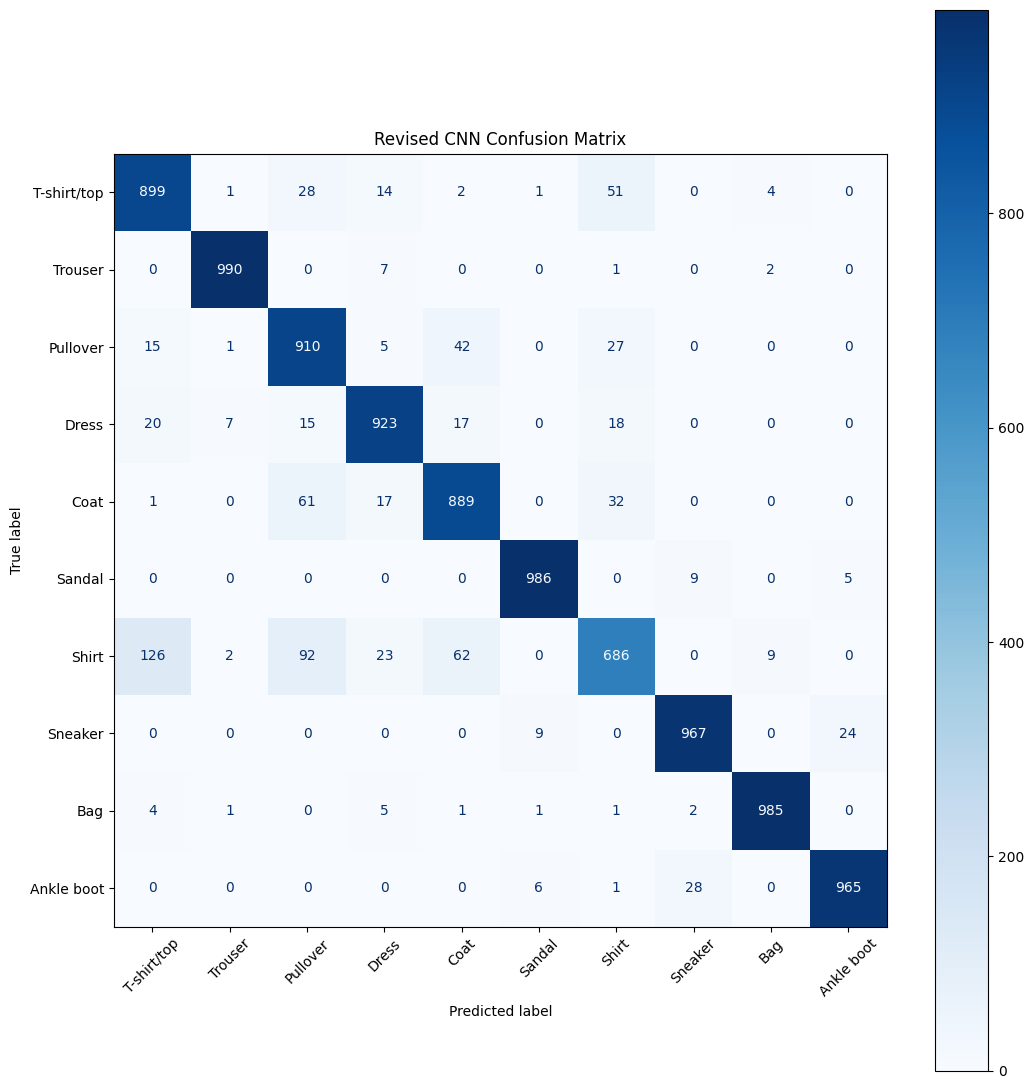

In [29]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

cm_v2 = confusion_matrix(y_test, labels_v2)

fig, ax = plt.subplots(figsize=(11, 11))

ConfusionMatrixDisplay(
    confusion_matrix=cm_v2,
    display_labels=class_names
).plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45,
    values_format="d"
)

plt.title("Revised CNN Confusion Matrix")
plt.tight_layout()
plt.show()

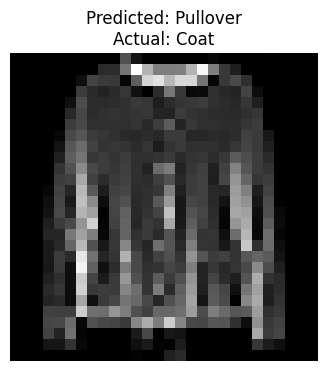

Predicted category: Pullover
Actual category: Coat
Prediction confidence: 75.00%
Correct prediction: False


In [30]:
# Select a test image
index = 25

image = X_test[index]

# Predict using the revised model
probabilities = model_v2.predict(
    image[np.newaxis, ...],
    verbose=0
)[0]

predicted_class = np.argmax(probabilities)
actual_class = y_test[index]

# Display the image and results
plt.figure(figsize=(4, 4))
plt.imshow(image.squeeze(), cmap="gray")
plt.title(
    f"Predicted: {class_names[predicted_class]}\n"
    f"Actual: {class_names[actual_class]}"
)
plt.axis("off")
plt.show()

print("Predicted category:", class_names[predicted_class])
print("Actual category:", class_names[actual_class])
print(f"Prediction confidence: {probabilities[predicted_class]:.2%}")
print(f"Correct prediction: {predicted_class == actual_class}")

In [31]:
for name, probability in sorted(
    zip(class_names, probabilities),
    key=lambda item: item[1],
    reverse=True
):
    print(f"{name}: {probability:.2%}")

Pullover: 75.00%
Shirt: 16.19%
Coat: 8.81%
T-shirt/top: 0.01%
Trouser: 0.00%
Dress: 0.00%
Bag: 0.00%
Sandal: 0.00%
Ankle boot: 0.00%
Sneaker: 0.00%


In [32]:
model_v2.save("clothing_classifier.keras")

from google.colab import files
files.download("clothing_classifier.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>